In [1]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import re
import csv
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

from HELPER_FREEFLUX_NF import io as nf_io
import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt

from analysis import config_13c as config

ModuleNotFoundError: No module named 'freeflux'

### compare optimal flux and confidence interval with different moethods (for classic 13C) and with our approach

In [ ]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [ ]:
condition='WT' 
model=config.model
net_flux_df=config.net_flux_df(condition)
obj_vals=config.obj_vals(condition)
nperc=10
accepted_samples=obj_vals[obj_vals<= np.percentile(obj_vals,nperc)].index
color=palette[0] if condition=='WT' else palette[2]


In [ ]:

NLP_FOLDER=f'{config.FREEFLUXRUN_FOLDER}/classic_13c/NLPCI/WSS/'


cPU=$1
HOURS=$2
MEMORY=$3
CONDITION=$4
LABELING_STRAT="combined"
DATASET="mixed"
SAMPLE=$5
N_RESTARTS=$6
MAX_ITERS=$7


## load model and fluxes 

In [ ]:
#load pathway df and cmodel
## read yeast excel model file and get subsystem for each rxn 
excel_model=f'{config.INPUT_FOLDER}/yeast_v3.211_starting_curated_withprotons.xlsx'
tmp=pd.read_excel(excel_model,sheet_name='Reactions',index_col=0)['Subsystem']
tmp_trsp=pd.read_excel(excel_model,sheet_name='Transmembrane reactions',index_col=0)['Subsystem']
df_pathways=pd.concat([tmp,tmp_trsp])


/home/nathan/anaconda3/envs/13C_INCA/lib/python3.11/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
/home/nathan/anaconda3/envs/13C_INCA/lib/python3.11/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Conditional Formatting extension is not supported and will be removed
  for idx, row in parser.parse():
/home/nathan/anaconda3/envs/13C_INCA/lib/python3.11/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
/home/nathan/anaconda3/envs/13C_INCA/lib/python3.11/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Conditional Formatting extension is not supported and will be removed
  for idx, row in parser.parse():


## on the cluster i ran NLP search. 2 files for each flux (min,max); header is optimized flux

In [ ]:
files=[f for f in os.listdir(NLP_FOLDER) if f.endswith('.csv') and condition in f]
## create a df with {flux_idx: [min,max]}
df_NLPCI=pd.DataFrame(columns=['min','max'])

for f in files:
    print(f)
    flux_idx=int(re.findall('(?<=flux)(\d{1,3})',f)[0])
    file_name=f'{NLP_FOLDER}/{f}'
    with open(file_name, newline='') as csvfile:
        opt_u = list(csv.reader(csvfile))
    obj_val=float(opt_u[0][0].replace('# ',''))
    dir=int(re.findall('(?<=direction)\d',f)[0])
    if dir==1:
        df_NLPCI.loc[flux_idx,'max']=obj_val
    else:
        df_NLPCI.loc[flux_idx,'min']=obj_val
    print(obj_val,dir,flux_idx) 



optu_WT_flux24_direction1_classicNLPCI.csv
1.5864365581874362 1 24
optu_WT_flux71_direction0_classicNLPCI.csv
13.040547754695133 0 71
optu_WT_flux16_direction0_classicNLPCI.csv
0.04043167479951808 0 16
optu_WT_flux10_direction1_classicNLPCI.csv
-0.12784418205913742 1 10
optu_WT_flux92_direction0_classicNLPCI.csv
-0.1857369044120249 0 92
optu_WT_flux172_direction0_classicNLPCI.csv
-0.6250011516689583 0 172
optu_WT_flux134_direction1_classicNLPCI.csv
-0.0943249621783748 1 134
optu_WT_flux127_direction0_classicNLPCI.csv
0.07582654587244263 0 127
optu_WT_flux120_direction0_classicNLPCI.csv
0.07433050366115021 0 120
optu_WT_flux160_direction1_classicNLPCI.csv
0.002378268132768767 1 160
optu_WT_flux117_direction0_classicNLPCI.csv
-0.06331555336455491 0 117
optu_WT_flux20_direction1_classicNLPCI.csv
0.05933290338052728 1 20
optu_WT_flux146_direction0_classicNLPCI.csv
0.15932641149590665 0 146
optu_WT_flux90_direction1_classicNLPCI.csv
0.2196228299660259 1 90
optu_WT_flux27_direction0_classicN

In [ ]:
match_index_id={i:id for i,id in enumerate(model.netfluxids)}
df_NLPCI.index=[match_index_id[int(i)] for i in df_NLPCI.index]
for rid in df_NLPCI.index:
    if df_NLPCI.loc[rid,'max'] >= df_NLPCI.loc[rid,'min']:
        df_NLPCI.loc[rid,'range'] = df_NLPCI.loc[rid,'max'] - df_NLPCI.loc[rid,'min']
    else :  ##problem in nlp_opt_singleflux ?
        df_NLPCI.loc[rid,'max']=abs(df_NLPCI.loc[rid,'max'])
        df_NLPCI.loc[rid,'range'] = df_NLPCI.loc[rid,'max'] - df_NLPCI.loc[rid,'min']
# df_NLPCI['range'] = df_NLPCI['max'] - df_NLPCI['min']
# df_NLPCI['range'] = df_NLPCI['range'].clip(lower=1e-6)
# ## replace nan by 1e-6

# df_NLPCI['range'] = df_NLPCI['range'].fillna(1e-6)


# df_NLPCI

In [ ]:
df_NLPCI

,min,max,range
ampSYN1,-0.151453,1.586437,1.737889
PFK,13.040548,14.20704,1.166492
ARGSL,0.040432,0.057897,0.017465
MALS,0.000653,0.127844,0.127192
MDH,-0.185737,0.053141,0.238877
...,...,...,...
G6PDH2,0.099896,0.296867,0.196971
GHMT2,0.089948,0.118169,0.028221
GLYK,-0.668358,1.104865,1.773223
GLNtm,1.222845,1.855566,0.632721


## load VA ranges 


In [ ]:
##load data_VA_boudns data_bounds_fluxes_all_2ndlaw.csv in 4
df_VAbounds=pd.read_csv(f'{config.RESULTS_FOLDER}/a_fluxspace/202601_13C_tf01_flux_bounds_{condition}.csv',index_col=0)


In [ ]:
#based on va bounds, exclude reaction which ranges is 0 ; dont want to take them for the plot ; its close to 0 for all methods
dftmp=df_VAbounds[(df_VAbounds['lb']!=0) | (df_VAbounds['ub']!=0)]
rxn_zero=[i for i in df_VAbounds.index if i not in dftmp.index]
rxn_zero

['Galkin',
 'Gal7',
 'Gal10',
 'Mankin',
 'M6pism',
 'MALTGD',
 'gal-D_EX',
 'man-D_EX',
 'malt_EX',
 'GALt+0',
 'Mant+0',
 'MALTt+1']

## plotss

In [ ]:
##make a function that takes a df as input and plots min max range as vertical bars
def plot_ranges(ax,df_data,title=None,**kwargs):
    '''plot flux ranges as vertical barsfrom col 0 to col 1'''
    x=np.arange(1,len(df_data)+1)
    y1=df_data.iloc[:,0]
    y2=df_data.iloc[:,1]
    bottoms=np.minimum(y1,y2)
    heights=np.abs(y1-y2)
    ax.vlines(x=x,ymin=bottoms,ymax=bottoms+heights,**kwargs)
    # ax.set_title(title)
    

    

In [ ]:
df_VAbounds['range']=df_VAbounds['ub']-df_VAbounds['lb']
df_VAbounds.sort_values('range',ascending=False)

,lb,ub,range
ampSYN2,-499.959063,499.998188,999.957250
gmpSYN1,-499.965059,499.991742,999.956801
ampSYN1,-499.956888,0.042139,499.999027
CITMALtm-3+H-2,-92.776109,56.325148,149.101256
PItm-2+H,-52.830962,91.211763,144.042724
...,...,...,...
Gal7,0.000000,-0.000000,-0.000000
man-D_EX,0.000000,-0.000000,-0.000000
Gal10,0.000000,-0.000000,-0.000000
MALTGD,0.000000,-0.000000,-0.000000


## 4 density plots

In [ ]:
def kdplot(data,**kwargs):
    sns.kdeplot(data,linewidth=3,cumulative=False,**kwargs)

In [ ]:
df_VAbounds

,lb,ub,range
ASNS1,0.034071,0.036976,0.002905
ASPK,0.019196,18.146436,18.127240
ASPTA,-44.894585,65.774571,110.669156
ASPTAm,-66.861842,44.452635,111.314476
ASAD,0.019196,18.146436,18.127240
...,...,...,...
GALt+0,0.000000,-0.000000,-0.000000
Mant+0,0.000000,-0.000000,-0.000000
MALTt+1,0.000000,-0.000000,-0.000000
biomass_ce,0.335013,0.363581,0.028568


In [ ]:
def rel_halfrange(lo, hi):
    '''half flux range divided by |midpoint|; >1 means the interval crosses zero'''
    lo, hi = lo.astype(float), hi.astype(float)
    r = (hi - lo) / (hi + lo).abs()
    return r.replace([np.inf, -np.inf], np.nan).dropna()

def kdplot(data, **kwargs):
    sns.kdeplot(data, linewidth=3, cumulative=False, log_scale=True, **kwargs)

rxn_picked = [i for i in df_NLPCI.index if i in df_VAbounds.index and i not in rxn_zero]

rel = {
    'VA bounds': rel_halfrange(df_VAbounds.loc[rxn_picked, 'lb'], df_VAbounds.loc[rxn_picked, 'ub']),
    'NLP CI':    rel_halfrange(df_NLPCI.loc[rxn_picked, 'min'], df_NLPCI.loc[rxn_picked, 'max']),
}

fig, axes = plt.subplots(len(rel), 1, figsize=(2.5, 1.25), sharex=True)
io_func.scale_rcparams(fig)

for ax, (label, r) in zip(axes, rel.items()):
    kdplot(r, color=palette[0], label=label, ax=ax)
    ax.axvline(1, color='grey', linestyle='--', linewidth=1)   # >1: crosses zero
    ax.text(0.98, 0.9, f'{(r > 1).mean():.0%} cross 0', transform=ax.transAxes,
            ha='right', va='top', fontsize=10)
    ax.set_ylabel('')
    ax.set_yticks([])

axes[-1].set_xlabel('Flux range \nrelative to midpoint')
axes[-1].set_xticks([1e-2, 1, 1e2])
##savefig 
# fig.savefig(f'{config.PLOTS_FOLDER}/fig5f_range_normmean_classic_kdeplot_WT.svg', dpi=300, bbox_inches='tight')

NameError: name 'df_NLPCI' is not defined

plot flux ranges of classic 13C  for a few reactions 

In [53]:
def plotbarplot2(rxn_list, df_va, ax, offset=0, capsize=5, **kwargs):
    for i, rxn in enumerate(rxn_list):
        lb = df_va.loc[rxn, 'min']
        ub = df_va.loc[rxn, 'max']
        center = (lb + ub) / 2
        half_range = (ub - lb) / 2

        # Plot a horizontal line with caps at both ends
        ax.errorbar(
            center, i + offset,
            xerr=half_range,
            fmt='none',               # No central marker
            ecolor=kwargs.get('color', 'black'),
            elinewidth=kwargs.get('linewidth', 1),
            capsize=capsize,
            capthick=kwargs.get('linewidth', 1),
        )

In [102]:
df_NLPCI

,min,max,range
ampSYN1,-0.151453,1.586437,1.737889
PFK,13.040548,14.20704,1.166492
ARGSL,0.040432,0.057897,0.017465
MALS,0.000653,0.127844,0.127192
MDH,-0.185737,0.053141,0.238877
...,...,...,...
G6PDH2,0.099896,0.296867,0.196971
GHMT2,0.089948,0.118169,0.028221
GLYK,-0.668358,1.104865,1.773223
GLNtm,1.222845,1.855566,0.632721


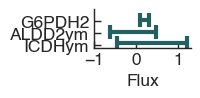

In [ ]:
###plot 2 reactions : ICDHym and PGM
import matplotlib.pyplot as plt

# assume df is your dataframe
fig, ax = plt.subplots(figsize=(1.25, 0.5))
rxn_list=['ICDHym','ALDD2ym','G6PDH2']
# dfbarp=df_VAbounds.loc[rxn_list]
# y = range(len(dfbarp))

# ax.barh(y, dfbarp["ub"] - dfbarp["lb"], left=dfbarp["lb"],alpha=0.3)

plotbarplot2(rxn_list,df_NLPCI,ax,offset=0.1,color=sns.color_palette(palette)[0],label='WT',linewidth=3)

ax.set_yticks(np.arange(len(rxn_list)))
ax.set_yticklabels(rxn_list)

ax.set_xlabel("Flux")
ax.set_ylim(-0.25,3)
ax.set_xticks([-1,0,1])

##save fig 

# plt.savefig(f'{config.PLOTS_FOLDER}/fig5a_comparisonclassic_3rxn_NLPCIrange_WT.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}/fig5a_comparisonclassic_3rxn_NLPCIrange_WT.svg',dpi=300,bbox_inches='tight')
